# RQ20 — Final generalization-regime synthesis and deployment decision map

## Scientific question

**What generalization regimes are actually supported by the completed PhageLysClass benchmark, and which modeling strategies are most defensible for different deployment objectives?**

RQ20 is the **final synthesis notebook**. It does not train new models, reopen model selection, or construct a universal leaderboard. It integrates the frozen evidence from RQ1–RQ19 into two outputs:

1. a **generalization-regime map** describing which factors limit each biological task; and
2. a **scenario-specific deployment map** describing which strategies are defensible for different operational goals.

The central principle is:

> **There is no universally best model independent of the decision problem.**

A strategy can be attractive for routine supervised inference, remote-homology generalization, strict R/S deployment, PU recovery, candidate discovery, or experimental prioritization for different reasons.

### Primary synthesis dimensions

RQ20 integrates:

- task/evidence formulation;
- redundancy sensitivity;
- homology-separation sensitivity;
- R×S non-additivity;
- representation dependence;
- PLM-capacity dependence;
- downstream learner dependence;
- finite-test uncertainty;
- computational burden;
- PU learning paradigm;
- candidate-discovery behavior;
- evidence scarcity.

### Deployment is scenario-specific

The notebook distinguishes at least:

- **maximum supervised predictive performance**;
- **compute-aware supervised deployment**;
- **remote-homology supervised deployment**;
- **jointly stringent R30/S30 deployment**;
- **PU known-positive recovery**;
- **PU candidate discovery**;
- **legacy/weak-representation PU settings**;
- **Low-N / evidence-limited tasks**;
- **experimental candidate follow-up**.

No single scalar combines predictive performance, runtime, uncertainty, and biological support.

## Interpretation contract

The following rules are frozen before synthesis:

- Native Stage12 supervised results remain the authoritative benchmark outcomes.
- Common-test analyses are sensitivity analyses and never replace the native benchmark.
- `R` and `S` are **not interchangeable perturbations**:
  - `R` changes redundancy, available evidence, and the evaluated population;
  - `S` primarily changes the train–test homology relationship within a fixed R universe.
- Same-entity common-R results are secondary and do not isolate a pure causal training effect.
- Bootstrap intervals from RQ17 represent **finite-test uncertainty conditional on the fitted models**, not training-seed uncertainty.
- A bootstrap interval overlapping zero does **not** establish equivalence.
- The `≤0.02 MCC` near-best criterion from RQ18 is a descriptive sensitivity definition, not an equivalence margin.
- Representation extraction cost is separate from downstream learner runtime.
- Missing PU runtime instrumentation remains **not estimable**; no PU speed claim is manufactured here.
- `U` is unlabeled, never a confirmed negative class.
- Elkan–Noto upper-tail behavior remains clipping/tie-sensitive and is not promoted to a discovery strategy on the basis of U99.
- Known-positive recovery and candidate discovery are distinct PU objectives.
- VAL remains evidence-limited and must retain an explicit deployment guardrail.
- RQ19 candidates are **prioritized for experimental characterization**, not computationally validated lytic enzymes.

In [1]:
from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 280)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

TASK_LABELS = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "Depolymerase",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_LABELS = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

# Descriptive deployment tolerance inherited from RQ18; NOT a statistical equivalence margin.
DEPLOYMENT_NEAR_BEST_MCC = 0.02

T30 = "esm2_t30_150m"
T6 = "esm2_t6_8m"
ROXY = "roxy_48"
ONEHOT = "onehot_1024"

def find_project_root(start=None):
    override = os.environ.get("PHAGELYSCLASS_ROOT")
    if override:
        p = Path(override).expanduser().resolve()
        if (
            (p / "results/analysis_supervised/stage12a").is_dir()
            and (p / "results/analysis_supervised/notebook_cache").is_dir()
        ):
            return p
        raise FileNotFoundError(
            "PHAGELYSCLASS_ROOT was set but does not expose the required "
            "supervised analysis directories."
        )

    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/notebook_cache").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root. "
        "Set PHAGELYSCLASS_ROOT or execute the notebook from inside the project."
    )

ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"
PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"
RQ17_CACHE = ROOT / "results/analysis_bootstrap/rq17"
RQ18_CACHE = ROOT / "results/analysis_compute/rq18"
RQ19_FINAL = ROOT / "results/analysis_candidates/rq19_final"

RQ20_CACHE = ROOT / "results/analysis_synthesis/rq20"
RQ20_CACHE.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ20_CACHE:", RQ20_CACHE)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ20_CACHE: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20


## 1. Real-project preflight

In [2]:
PATHS = {
    "supervised_master": SUP_STAGE12A / "supervised_master_results.tsv",
    "rq9_fingerprint": SUP_CACHE / "rq9_functional_regime_fingerprint.tsv",
    "rq17_rep_uncertainty": RQ17_CACHE / "rq17_supervised_representation_uncertainty_summary.tsv",
    "rq17_alg_uncertainty": RQ17_CACHE / "rq17_supervised_algorithm_uncertainty_summary.tsv",
    "rq17_commonS_task_R": RQ17_CACHE / "rq17_commonS_uncertainty_by_task_R.tsv",
    "rq17_commonR_T30": RQ17_CACHE / "rq17_commonR_T30_uncertainty_by_S.tsv",
    "rq17_PU_method": RQ17_CACHE / "rq17_PU_method_uncertainty_by_representation.tsv",
    "rq17_PU_T30_T6": RQ17_CACHE / "rq17_PU_T30_T6_uncertainty_summary.tsv",
    "rq17_VAL": RQ17_CACHE / "rq17_VAL_uncertainty_summary.tsv",
    "rq18_efficiency_cells": RQ18_CACHE / "rq18_supervised_efficiency_cells.tsv",
    "rq18_pareto_summary": RQ18_CACHE / "rq18_pareto_summary.tsv",
    "rq12_PU_native": PU_CACHE / "rq12_pu_native_score_diagnostics.tsv",
    "rq15_evidence": PU_CACHE / "rq15_evidence_summary.tsv",
    "rq19_summary": RQ19_FINAL / "rq19_final_summary.tsv",
    "rq19_top20": RQ19_FINAL / "rq19_final_top20_evidence_panel.tsv",
}

OPTIONAL_PATHS = {
    "rq11_regime": SUP_CACHE / "rq11_regime_table.tsv",
    "rq16_evidence": SUP_CACHE / "rq16_evidence_summary.tsv",
    "rq18_prediction_time": RQ18_CACHE / "rq18_prediction_time_summary.tsv",
    "rq18_extraction_T30_T6": RQ18_CACHE / "rq18_representation_extraction_T30_T6.tsv",
    "rq18_PU_runtime_audit": RQ18_CACHE / "rq18_PU_runtime_discovery_audit.tsv",
}

preflight_rows = []

for name, path in PATHS.items():
    preflight_rows.append({
        "artifact": name,
        "required": True,
        "path": str(path),
        "present": path.is_file(),
    })

for name, path in OPTIONAL_PATHS.items():
    preflight_rows.append({
        "artifact": name,
        "required": False,
        "path": str(path),
        "present": path.is_file(),
    })

preflight = pd.DataFrame(preflight_rows)

display(preflight)

missing_required = preflight[
    preflight["required"] & ~preflight["present"]
]

if len(missing_required):
    raise FileNotFoundError(
        "RQ20 cannot synthesize the completed benchmark because required "
        "upstream cache files are missing:\n"
        + "\n".join(missing_required["path"].tolist())
    )

print("REAL_PROJECT_PREFLIGHT_OK — all mandatory RQ20 inputs are present.")

,artifact,required,path,present
0,supervised_master,True,/home/david/Desktop/colabs/inta_project/phagel...,True
1,rq9_fingerprint,True,/home/david/Desktop/colabs/inta_project/phagel...,True
2,rq17_rep_uncertainty,True,/home/david/Desktop/colabs/inta_project/phagel...,True
3,rq17_alg_uncertainty,True,/home/david/Desktop/colabs/inta_project/phagel...,True
4,rq17_commonS_task_R,True,/home/david/Desktop/colabs/inta_project/phagel...,True
5,rq17_commonR_T30,True,/home/david/Desktop/colabs/inta_project/phagel...,True
6,rq17_PU_method,True,/home/david/Desktop/colabs/inta_project/phagel...,True
7,rq17_PU_T30_T6,True,/home/david/Desktop/colabs/inta_project/phagel...,True
8,rq17_VAL,True,/home/david/Desktop/colabs/inta_project/phagel...,True
9,rq18_efficiency_cells,True,/home/david/Desktop/colabs/inta_project/phagel...,True


REAL_PROJECT_PREFLIGHT_OK — all mandatory RQ20 inputs are present.


## 2. Load frozen evidence tables and validate schemas

In [3]:
def read_tsv(path):
    return pd.read_csv(path, sep="\t", low_memory=False)

sup = read_tsv(PATHS["supervised_master"])
rq9 = read_tsv(PATHS["rq9_fingerprint"])
rep_unc = read_tsv(PATHS["rq17_rep_uncertainty"])
alg_unc = read_tsv(PATHS["rq17_alg_uncertainty"])
common_s_unc = read_tsv(PATHS["rq17_commonS_task_R"])
common_r_unc = read_tsv(PATHS["rq17_commonR_T30"])
pu_method_unc = read_tsv(PATHS["rq17_PU_method"])
pu_rep_unc = read_tsv(PATHS["rq17_PU_T30_T6"])
val_unc = read_tsv(PATHS["rq17_VAL"])
sup_eff = read_tsv(PATHS["rq18_efficiency_cells"])
rq18_pareto = read_tsv(PATHS["rq18_pareto_summary"])
pu_native = read_tsv(PATHS["rq12_PU_native"])
rq15_evidence = read_tsv(PATHS["rq15_evidence"])
rq19_summary = read_tsv(PATHS["rq19_summary"])
rq19_top20 = read_tsv(PATHS["rq19_top20"])

rq11_regime = (
    read_tsv(OPTIONAL_PATHS["rq11_regime"])
    if OPTIONAL_PATHS["rq11_regime"].is_file()
    else pd.DataFrame()
)

def require_columns(df, required, name):
    missing = set(required) - set(df.columns)
    if missing:
        raise KeyError(
            f"{name} is missing required columns: {sorted(missing)}"
        )

require_columns(
    sup,
    ["task", "R", "S", "representation", "algorithm", "mcc"],
    "supervised_master_results.tsv",
)
require_columns(
    rq9,
    [
        "task", "overall_mcc", "permissive_mcc", "strict_mcc",
        "worst_mcc", "R_signed", "R_abs", "S_signed", "S_abs",
        "RxS_interaction", "RxS_abs", "T30_minus_T6",
        "T30_minus_onehot", "representation_range",
        "algorithm_range", "rep_to_alg_ratio", "surface_range",
        "regime_signature",
    ],
    "rq9_functional_regime_fingerprint.tsv",
)
require_columns(
    rep_unc,
    [
        "contrast", "task", "n", "median_point_delta",
        "median_ci_width", "fraction_resolved_positive",
        "fraction_resolved_negative", "fraction_overlaps_zero",
    ],
    "RQ17 representation uncertainty",
)
require_columns(
    alg_unc,
    [
        "contrast", "task", "n", "median_point_delta",
        "median_ci_width", "fraction_resolved_positive",
        "fraction_resolved_negative", "fraction_overlaps_zero",
    ],
    "RQ17 algorithm uncertainty",
)
require_columns(
    common_s_unc,
    [
        "task", "R", "median_point_delta",
        "fraction_resolved_negative", "fraction_overlaps_zero",
        "median_ci_width",
    ],
    "RQ17 common-S uncertainty",
)
require_columns(
    common_r_unc,
    [
        "S", "median_point_delta", "median_ci_width",
        "fraction_resolved_negative", "fraction_resolved_positive",
        "fraction_overlaps_zero",
    ],
    "RQ17 common-R uncertainty",
)
require_columns(
    pu_method_unc,
    [
        "contrast", "representation", "n", "median_point_delta",
        "fraction_resolved_positive", "fraction_resolved_negative",
        "fraction_overlaps_zero",
    ],
    "RQ17 PU-method uncertainty",
)
require_columns(
    pu_rep_unc,
    [
        "method", "n", "median_point_delta",
        "fraction_resolved_positive", "fraction_resolved_negative",
        "fraction_overlaps_zero",
    ],
    "RQ17 PU representation uncertainty",
)
require_columns(
    val_unc,
    ["R", "S", "metric", "median_point_value", "median_ci_width", "median_n_positive"],
    "RQ17 VAL uncertainty",
)
require_columns(
    sup_eff,
    [
        "task", "R", "S", "representation", "algorithm", "mcc",
        "downstream_runtime_seconds", "pareto_efficient", "near_best_0p02",
    ],
    "RQ18 supervised efficiency cells",
)
require_columns(
    pu_native,
    [
        "task", "R", "S", "representation", "method", "algorithm",
        "fraction_P_above_U95", "median_P_percentile_vs_U",
    ],
    "RQ12 PU native diagnostics",
)
require_columns(
    rq15_evidence,
    [
        "method", "representation", "median_U95_gain_vs_naive",
        "fraction_U95_practical_tie", "median_method_pair_U_spearman",
        "median_fixed_top1_jaccard", "median_fixed_top5_jaccard",
    ],
    "RQ15 evidence summary",
)

if len(sup) != 2240:
    raise RuntimeError(
        f"Expected frozen supervised benchmark with 2240 families; observed {len(sup)}."
    )

if len(pu_native) != 768:
    raise RuntimeError(
        f"Expected frozen PU diagnostic table with 768 rows; observed {len(pu_native)}."
    )

if set(sup["task"]) != set(TASK_ORDER):
    raise RuntimeError(
        f"Unexpected supervised task universe: {sorted(sup['task'].unique())}"
    )

if set(sup["representation"]) != set(REP_ORDER):
    raise RuntimeError(
        "Unexpected supervised representation universe."
    )

if set(sup["algorithm"]) != set(ALG_ORDER):
    raise RuntimeError(
        "Unexpected supervised algorithm universe."
    )

print("SCHEMA_OK — all mandatory synthesis tables match the frozen contracts.")

SCHEMA_OK — all mandatory synthesis tables match the frozen contracts.


## 3. Mandatory synthesis-engine self-test

In [4]:
def pareto_mask(performance, runtime):
    perf = np.asarray(performance, dtype=float)
    rt = np.asarray(runtime, dtype=float)

    out = np.zeros(len(perf), dtype=bool)

    for i in range(len(perf)):
        if not (np.isfinite(perf[i]) and np.isfinite(rt[i])):
            continue

        dominated = (
            (perf >= perf[i])
            & (rt <= rt[i])
            & (
                (perf > perf[i])
                | (rt < rt[i])
            )
        )
        dominated[i] = False
        out[i] = not dominated.any()

    return out

def contrast_contains(df, *tokens):
    if "contrast" not in df.columns:
        return pd.Series(False, index=df.index)

    s = (
        df["contrast"]
        .astype(str)
        .str.lower()
        .str.replace("–", "-", regex=False)
        .str.replace("−", "-", regex=False)
    )

    mask = pd.Series(True, index=df.index)
    for token in tokens:
        mask &= s.str.contains(str(token).lower(), regex=False)
    return mask

def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    ok = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if not ok.any():
        return np.nan
    return float(np.average(values[ok], weights=weights[ok]))

def strategy_label(rep, alg):
    return f"{REP_LABELS.get(str(rep), str(rep))} + {alg}"

mask = pareto_mask(
    [0.80, 0.79, 0.82, 0.84],
    [2.0, 3.0, 4.0, 10.0],
)
assert mask.tolist() == [True, False, True, True]

test_contrasts = pd.DataFrame({
    "contrast": [
        "T30 - T6",
        "T30 - Roxy",
        "MLP - XGB",
    ]
})
assert contrast_contains(test_contrasts, "t30", "t6").tolist() == [True, False, False]
assert contrast_contains(test_contrasts, "mlp", "xgb").tolist() == [False, False, True]

assert strategy_label(T30, "KNN") == "ESM2-T30 + KNN"

print("SYNTHESIS_ENGINE_SELFTEST_OK — Pareto, contrast matching, and labeling passed.")

SYNTHESIS_ENGINE_SELFTEST_OK — Pareto, contrast matching, and labeling passed.


## 4. Frozen benchmark coverage audit

In [5]:
coverage = (
    sup.groupby(["task", "R", "S"])
    .agg(
        n_models=("mcc", "size"),
        n_representations=("representation", "nunique"),
        n_algorithms=("algorithm", "nunique"),
    )
    .reset_index()
)

expected_cells = len(TASK_ORDER) * len(R_LEVELS) * len(S_LEVELS)

if len(coverage) != expected_cells:
    raise RuntimeError(
        f"Expected {expected_cells} task×R×S cells; observed {len(coverage)}."
    )

if not coverage["n_models"].eq(20).all():
    raise RuntimeError("Every task×R×S cell must contain exactly 20 supervised models.")

display(
    coverage.groupby("task")
    .agg(
        n_rs_cells=("R", "size"),
        min_models=("n_models", "min"),
        max_models=("n_models", "max"),
    )
    .reindex(TASK_ORDER)
)

print("FROZEN_BENCHMARK_COVERAGE_OK")

,n_rs_cells,min_models,max_models
task,,,
global_easy,16,20,20
global_hard,16,20,20
global_mixed,16,20,20
subtype_endolysin,16,20,20
subtype_depolymerase,16,20,20
subtype_val,16,20,20
multiclass_clean,16,20,20


FROZEN_BENCHMARK_COVERAGE_OK


# Part I — Supervised deployment strategies

The same representation/learner pair is evaluated across all 16 R×S cells for each task.

RQ20 therefore creates **strategy profiles**, not a single score. For every `task × representation × learner`, it records:

- median MCC across the full R×S surface;
- minimum MCC across the surface;
- permissive R90/S90 MCC;
- jointly stringent R30/S30 MCC;
- median MCC at S30 across R;
- median MCC at R30 across S;
- RQ18 cell-wise Pareto frequency (reported descriptively);
- RQ18 near-best frequency;
- median downstream runtime.

Four scenario-specific selections are then made **lexicographically**, without combining these quantities into a scalar:

- `performance_oriented`: maximize median MCC, then worst-case MCC;
- `remote_homology`: maximize S30 performance;
- `joint_strict`: maximize R30/S30 performance;
- `compute_aware_near_best`: select the fastest strategy whose median MCC is within 0.02 of the best observed median MCC for that task. The 0.02 tolerance is descriptive and does not establish statistical equivalence.

These are retrospective benchmark summaries intended to support deployment decisions. They are not new train/test model-selection rules.

## 5. Build supervised strategy profiles

In [6]:
strategy_rows = []

for (task, rep, alg), grp in sup.groupby(
    ["task", "representation", "algorithm"],
    sort=False,
):
    if len(grp) != 16:
        raise RuntimeError(
            f"Incomplete R×S surface for {task} / {rep} / {alg}: {len(grp)} rows."
        )

    permissive = grp[grp["R"].eq(90) & grp["S"].eq(90)]["mcc"]
    strict = grp[grp["R"].eq(30) & grp["S"].eq(30)]["mcc"]

    if len(permissive) != 1 or len(strict) != 1:
        raise RuntimeError(
            f"Missing unique R90/S90 or R30/S30 corner for {task}/{rep}/{alg}."
        )

    strategy_rows.append({
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "strategy": strategy_label(rep, alg),
        "n_rs_cells": len(grp),
        "median_mcc": float(grp["mcc"].median()),
        "q25_mcc": float(grp["mcc"].quantile(0.25)),
        "worst_mcc": float(grp["mcc"].min()),
        "best_mcc": float(grp["mcc"].max()),
        "permissive_R90_S90_mcc": float(permissive.iloc[0]),
        "joint_strict_R30_S30_mcc": float(strict.iloc[0]),
        "S30_median_mcc": float(grp.loc[grp["S"].eq(30), "mcc"].median()),
        "R30_median_mcc": float(grp.loc[grp["R"].eq(30), "mcc"].median()),
    })

strategy = pd.DataFrame(strategy_rows)

eff_summary = (
    sup_eff.groupby(
        ["task", "representation", "algorithm"],
        as_index=False,
    )
    .agg(
        pareto_rate=("pareto_efficient", "mean"),
        near_best_rate=("near_best_0p02", "mean"),
        median_runtime_s=("downstream_runtime_seconds", "median"),
        q90_runtime_s=("downstream_runtime_seconds", lambda x: x.quantile(0.90)),
        median_cell_gap_to_best=(
            "mcc_gap_to_cell_best",
            "median",
        ) if "mcc_gap_to_cell_best" in sup_eff.columns else (
            "mcc", lambda x: np.nan
        ),
    )
)

strategy = strategy.merge(
    eff_summary,
    on=["task", "representation", "algorithm"],
    how="left",
    validate="one_to_one",
)

if strategy[["pareto_rate", "near_best_rate", "median_runtime_s"]].isna().any().any():
    raise RuntimeError(
        "RQ18 efficiency evidence did not map completely onto supervised strategies."
    )

display(
    strategy.sort_values(
        ["task", "median_mcc"],
        ascending=[True, False],
    )
)

,task,representation,algorithm,strategy,n_rs_cells,median_mcc,q25_mcc,worst_mcc,best_mcc,permissive_R90_S90_mcc,joint_strict_R30_S30_mcc,S30_median_mcc,R30_median_mcc,pareto_rate,near_best_rate,median_runtime_s,q90_runtime_s,median_cell_gap_to_best
17,global_easy,esm2_t30_150m,KNN,ESM2-T30 + KNN,16,0.937661,0.912092,0.883696,0.962580,0.962580,0.887662,0.928875,0.889012,1.0000,1.0000,2.857057,6.007964,0.000000
19,global_easy,esm2_t30_150m,MLP,ESM2-T30 + MLP,16,0.936167,0.909223,0.869458,0.963380,0.960914,0.877293,0.930812,0.879362,0.3750,0.8750,78.744082,130.800458,0.003133
18,global_easy,esm2_t30_150m,XGB,ESM2-T30 + XGB,16,0.924253,0.903063,0.871548,0.956669,0.956669,0.879389,0.924946,0.876619,0.1250,0.8750,94.989578,132.072724,0.011294
15,global_easy,esm2_t30_150m,LR,ESM2-T30 + LR,16,0.900628,0.869832,0.826977,0.929346,0.929346,0.840543,0.893512,0.832273,0.0000,0.0000,11.152947,12.043655,0.038935
16,global_easy,esm2_t30_150m,RF,ESM2-T30 + RF,16,0.883233,0.856083,0.813950,0.931977,0.931977,0.831723,0.873269,0.830138,0.0000,0.0000,53.275322,98.411428,0.053154
14,global_easy,esm2_t6_8m,MLP,ESM2-T6 + MLP,16,0.834057,0.804189,0.756088,0.908350,0.905664,0.801661,0.819513,0.783994,0.0000,0.0000,84.104476,125.338257,0.087074
13,global_easy,esm2_t6_8m,XGB,ESM2-T6 + XGB,16,0.830128,0.801661,0.762466,0.887374,0.887374,0.782209,0.824209,0.776060,0.0000,0.0000,52.621760,67.780089,0.105141
12,global_easy,esm2_t6_8m,KNN,ESM2-T6 + KNN,16,0.818084,0.783741,0.751080,0.890791,0.890791,0.756290,0.802731,0.763177,0.8125,0.0000,2.380511,5.435327,0.118306
11,global_easy,esm2_t6_8m,RF,ESM2-T6 + RF,16,0.755792,0.737406,0.688509,0.828414,0.818924,0.688509,0.753520,0.697747,0.0000,0.0000,31.666461,60.516176,0.176212
10,global_easy,esm2_t6_8m,LR,ESM2-T6 + LR,16,0.725336,0.705375,0.675837,0.777173,0.774966,0.698308,0.723273,0.689298,0.0000,0.0000,12.423226,13.876336,0.195613


## 6. Strategy-level performance/runtime Pareto front

In [7]:
frontier_parts = []

for task, grp in strategy.groupby("task", sort=False):
    g = grp.copy()
    g["strategy_level_pareto"] = pareto_mask(
        g["median_mcc"].to_numpy(),
        g["median_runtime_s"].to_numpy(),
    )
    frontier_parts.append(g)

strategy_frontier = pd.concat(frontier_parts, ignore_index=True)

display(
    strategy_frontier[
        strategy_frontier["strategy_level_pareto"]
    ].sort_values(
        ["task", "median_runtime_s"]
    )
)

,task,representation,algorithm,strategy,n_rs_cells,median_mcc,q25_mcc,worst_mcc,best_mcc,permissive_R90_S90_mcc,joint_strict_R30_S30_mcc,S30_median_mcc,R30_median_mcc,pareto_rate,near_best_rate,median_runtime_s,q90_runtime_s,median_cell_gap_to_best,strategy_level_pareto
2,global_easy,roxy_48,KNN,Roxy + KNN,16,0.652242,0.612121,0.569305,0.770957,0.770957,0.569305,0.632415,0.586748,1.0000,0.0000,1.843818,3.673646,0.281030,True
12,global_easy,esm2_t6_8m,KNN,ESM2-T6 + KNN,16,0.818084,0.783741,0.751080,0.890791,0.890791,0.756290,0.802731,0.763177,0.8125,0.0000,2.380511,5.435327,0.118306,True
17,global_easy,esm2_t30_150m,KNN,ESM2-T30 + KNN,16,0.937661,0.912092,0.883696,0.962580,0.962580,0.887662,0.928875,0.889012,1.0000,1.0000,2.857057,6.007964,0.000000,True
20,global_hard,roxy_48,LR,Roxy + LR,16,0.836442,0.823702,0.809975,0.884132,0.855871,0.821283,0.839401,0.823316,1.0000,0.0000,0.303357,0.377859,0.105419,True
32,global_hard,esm2_t6_8m,KNN,ESM2-T6 + KNN,16,0.927067,0.916347,0.895484,0.958064,0.957920,0.903153,0.933653,0.902898,0.8125,0.6875,0.645913,0.950805,0.017075,True
37,global_hard,esm2_t30_150m,KNN,ESM2-T30 + KNN,16,0.941970,0.910699,0.889481,0.964477,0.964477,0.904025,0.932870,0.900584,0.6875,0.8125,0.788295,0.963610,0.007999,True
38,global_hard,esm2_t30_150m,XGB,ESM2-T30 + XGB,16,0.942774,0.929148,0.900904,0.959317,0.959317,0.900904,0.939998,0.910262,0.1250,1.0000,38.183011,54.148785,0.006147,True
42,global_mixed,roxy_48,KNN,Roxy + KNN,16,0.643167,0.621482,0.552618,0.776994,0.776994,0.552618,0.621240,0.586852,1.0000,0.0000,1.870918,3.966474,0.277853,True
52,global_mixed,esm2_t6_8m,KNN,ESM2-T6 + KNN,16,0.821599,0.781067,0.749415,0.892410,0.892377,0.749415,0.786235,0.762537,0.8750,0.0000,2.639705,5.820607,0.101660,True
57,global_mixed,esm2_t30_150m,KNN,ESM2-T30 + KNN,16,0.927245,0.908315,0.873647,0.963493,0.950562,0.873647,0.913086,0.883819,1.0000,1.0000,3.132747,6.592040,0.000000,True


## 7. Scenario-specific supervised deployment map

In [8]:
def select_first(grp, sort_cols, ascending):
    return (
        grp.sort_values(
            sort_cols,
            ascending=ascending,
            kind="stable",
        )
        .iloc[0]
    )

def fastest_within_tolerance(
    grp,
    metric_col,
    tolerance=DEPLOYMENT_NEAR_BEST_MCC,
):
    """
    Compute-aware deployment rule:
    choose the fastest strategy whose target performance is within
    `tolerance` MCC of the best observed strategy for the same task/scenario.

    The tolerance is descriptive and does NOT imply statistical equivalence.
    """
    g = grp.copy()
    best_value = float(g[metric_col].max())

    eligible = g[
        g[metric_col].ge(
            best_value - tolerance
        )
    ].copy()

    if len(eligible) == 0:
        raise RuntimeError(
            f"No strategy remained within {tolerance:.3f} MCC of "
            f"best {metric_col}={best_value:.4f}."
        )

    selected = select_first(
        eligible,
        [
            "median_runtime_s",
            metric_col,
            "near_best_rate",
            "pareto_rate",
        ],
        [
            True,
            False,
            False,
            False,
        ],
    )

    return selected, best_value, len(eligible)

def strategy_set_within_tolerance(
    grp,
    metric_col,
    tolerance=DEPLOYMENT_NEAR_BEST_MCC,
):
    best_value = float(
        grp[metric_col].max()
    )

    eligible = (
        grp[
            grp[metric_col].ge(
                best_value - tolerance
            )
        ]
        .sort_values(
            [
                metric_col,
                "median_runtime_s",
            ],
            ascending=[
                False,
                True,
            ],
            kind="stable",
        )
    )

    return "; ".join(
        eligible["strategy"].astype(str)
    )

deployment_rows = []

for task in TASK_ORDER:
    g = strategy_frontier[
        strategy_frontier["task"].eq(task)
    ].copy()

    perf = select_first(
        g,
        ["median_mcc", "worst_mcc", "joint_strict_R30_S30_mcc", "median_runtime_s"],
        [False, False, False, True],
    )

    remote = select_first(
        g,
        ["S30_median_mcc", "worst_mcc", "median_mcc", "median_runtime_s"],
        [False, False, False, True],
    )

    strict = select_first(
        g,
        ["joint_strict_R30_S30_mcc", "worst_mcc", "median_mcc", "median_runtime_s"],
        [False, False, False, True],
    )

    # Correct compute-aware rule:
    # fastest model within 0.02 MCC of the task's best median MCC.
    efficient, best_task_mcc, n_compute_candidates = fastest_within_tolerance(
        g,
        "median_mcc",
    )

    competitive_sets = {
        "performance_oriented": strategy_set_within_tolerance(
            g,
            "median_mcc",
        ),
        "remote_homology": strategy_set_within_tolerance(
            g,
            "S30_median_mcc",
        ),
        "joint_strict": strategy_set_within_tolerance(
            g,
            "joint_strict_R30_S30_mcc",
        ),
        "compute_aware_near_best": strategy_set_within_tolerance(
            g,
            "median_mcc",
        ),
    }

    for objective, row, primary_metric in [
        ("performance_oriented", perf, "median_mcc"),
        ("remote_homology", remote, "S30_median_mcc"),
        ("joint_strict", strict, "joint_strict_R30_S30_mcc"),
        ("compute_aware_near_best", efficient, "median_mcc_within_0p02_then_runtime"),
    ]:
        deployment_rows.append({
            "domain": "supervised",
            "task": task,
            "objective": objective,
            "representation": row["representation"],
            "algorithm_or_paradigm": row["algorithm"],
            "strategy": row["strategy"],
            "selection_basis": primary_metric,
            "competitive_strategies_within_0p02": competitive_sets[objective],
            "median_mcc": row["median_mcc"],
            "worst_mcc": row["worst_mcc"],
            "S30_median_mcc": row["S30_median_mcc"],
            "joint_strict_R30_S30_mcc": row["joint_strict_R30_S30_mcc"],
            "pareto_rate": row["pareto_rate"],
            "near_best_rate": row["near_best_rate"],
            "median_downstream_runtime_s": row["median_runtime_s"],
            "guardrail": (
                "Evidence-limited: do not treat as standalone high-confidence deployment."
                if task == "subtype_val"
                else (
                    "Multiclass discrimination is a different biological decision problem from binary subtype recognition."
                    if task == "multiclass_clean"
                    else "Observed-best and within-0.02 strategies are descriptive benchmark references, not statistically proven superiority/equivalence."
                )
            ),
        })

supervised_deployment = pd.DataFrame(deployment_rows)

display(
    supervised_deployment[
        [
            "task", "objective", "strategy",
            "competitive_strategies_within_0p02",
            "median_mcc", "worst_mcc",
            "S30_median_mcc", "joint_strict_R30_S30_mcc",
            "pareto_rate", "near_best_rate",
            "median_downstream_runtime_s",
        ]
    ]
)

,task,objective,strategy,competitive_strategies_within_0p02,median_mcc,worst_mcc,S30_median_mcc,joint_strict_R30_S30_mcc,pareto_rate,near_best_rate,median_downstream_runtime_s
0,global_easy,performance_oriented,ESM2-T30 + KNN,ESM2-T30 + KNN; ESM2-T30 + MLP; ESM2-T30 + XGB,0.937661,0.883696,0.928875,0.887662,1.0000,1.0000,2.857057
1,global_easy,remote_homology,ESM2-T30 + MLP,ESM2-T30 + MLP; ESM2-T30 + KNN; ESM2-T30 + XGB,0.936167,0.869458,0.930812,0.877293,0.3750,0.8750,78.744082
2,global_easy,joint_strict,ESM2-T30 + KNN,ESM2-T30 + KNN; ESM2-T30 + XGB; ESM2-T30 + MLP,0.937661,0.883696,0.928875,0.887662,1.0000,1.0000,2.857057
3,global_easy,compute_aware_near_best,ESM2-T30 + KNN,ESM2-T30 + KNN; ESM2-T30 + MLP; ESM2-T30 + XGB,0.937661,0.883696,0.928875,0.887662,1.0000,1.0000,2.857057
4,global_hard,performance_oriented,ESM2-T30 + XGB,ESM2-T30 + XGB; ESM2-T30 + KNN; ESM2-T30 + RF;...,0.942774,0.900904,0.939998,0.900904,0.1250,1.0000,38.183011
5,global_hard,remote_homology,ESM2-T30 + LR,ESM2-T30 + LR; ESM2-T30 + RF; ESM2-T30 + XGB; ...,0.937556,0.885758,0.943219,0.885758,0.3750,0.8125,6.206784
6,global_hard,joint_strict,ESM2-T30 + RF,ESM2-T30 + RF; ESM2-T6 + XGB; ESM2-T30 + KNN; ...,0.940510,0.915296,0.942792,0.915296,0.5000,1.0000,9.318324
7,global_hard,compute_aware_near_best,ESM2-T6 + KNN,ESM2-T30 + XGB; ESM2-T30 + KNN; ESM2-T30 + RF;...,0.927067,0.895484,0.933653,0.903153,0.8125,0.6875,0.645913
8,global_mixed,performance_oriented,ESM2-T30 + KNN,ESM2-T30 + KNN; ESM2-T30 + MLP; ESM2-T30 + XGB,0.927245,0.873647,0.913086,0.873647,1.0000,1.0000,3.132747
9,global_mixed,remote_homology,ESM2-T30 + MLP,ESM2-T30 + MLP; ESM2-T30 + KNN; ESM2-T30 + XGB,0.923688,0.864446,0.917119,0.881569,0.3750,1.0000,107.806565


## 8. Cross-task supervised defaults

In [9]:
global_strategy = (
    strategy.groupby(
        ["representation", "algorithm", "strategy"],
        as_index=False,
    )
    .agg(
        median_mcc=("median_mcc", "median"),
        median_worst_mcc=("worst_mcc", "median"),
        median_strict_mcc=("joint_strict_R30_S30_mcc", "median"),
        median_S30_mcc=("S30_median_mcc", "median"),
        median_pareto_rate=("pareto_rate", "median"),
        median_near_best_rate=("near_best_rate", "median"),
        median_runtime_s=("median_runtime_s", "median"),
    )
)

global_performance = select_first(
    global_strategy,
    ["median_mcc", "median_worst_mcc", "median_strict_mcc", "median_runtime_s"],
    [False, False, False, True],
)

# Cross-task compute-aware near-best reference:
# fastest strategy within 0.02 MCC of the best cross-task median MCC.
best_global_mcc = float(
    global_strategy[
        "median_mcc"
    ].max()
)

global_compute_candidates = global_strategy[
    global_strategy[
        "median_mcc"
    ].ge(
        best_global_mcc
        - DEPLOYMENT_NEAR_BEST_MCC
    )
].copy()

if len(global_compute_candidates) == 0:
    raise RuntimeError(
        "No cross-task strategy remained within the deployment tolerance."
    )

global_efficient = select_first(
    global_compute_candidates,
    [
        "median_runtime_s",
        "median_mcc",
        "median_near_best_rate",
        "median_pareto_rate",
    ],
    [
        True,
        False,
        False,
        False,
    ],
)

global_supervised_defaults = pd.DataFrame([
    {
        "objective": "cross_task_performance_reference",
        **global_performance.to_dict(),
        "selection_note": (
            "Observed-best cross-task median MCC; exact learner superiority "
            "is not implied."
        ),
    },
    {
        "objective": "cross_task_compute_aware_near_best_reference",
        **global_efficient.to_dict(),
        "selection_note": (
            "Fastest strategy within 0.02 MCC of the best cross-task median MCC; "
            "0.02 is descriptive, not a statistical equivalence margin."
        ),
    },
])

display(global_supervised_defaults)

,objective,representation,algorithm,strategy,median_mcc,median_worst_mcc,median_strict_mcc,median_S30_mcc,median_pareto_rate,median_near_best_rate,median_runtime_s,selection_note
0,cross_task_performance_reference,esm2_t30_150m,KNN,ESM2-T30 + KNN,0.927245,0.859939,0.887662,0.913945,0.9375,0.8125,2.381881,Observed-best cross-task median MCC; exact lea...
1,cross_task_compute_aware_near_best_reference,esm2_t30_150m,KNN,ESM2-T30 + KNN,0.927245,0.859939,0.887662,0.913945,0.9375,0.8125,2.381881,Fastest strategy within 0.02 MCC of the best c...


The cross-task rows are **reference defaults**, not replacements for task-specific choices. If a biological task occupies a distinct regime, its task-specific deployment row takes precedence.

## 9. Visual audit — supervised performance versus downstream runtime

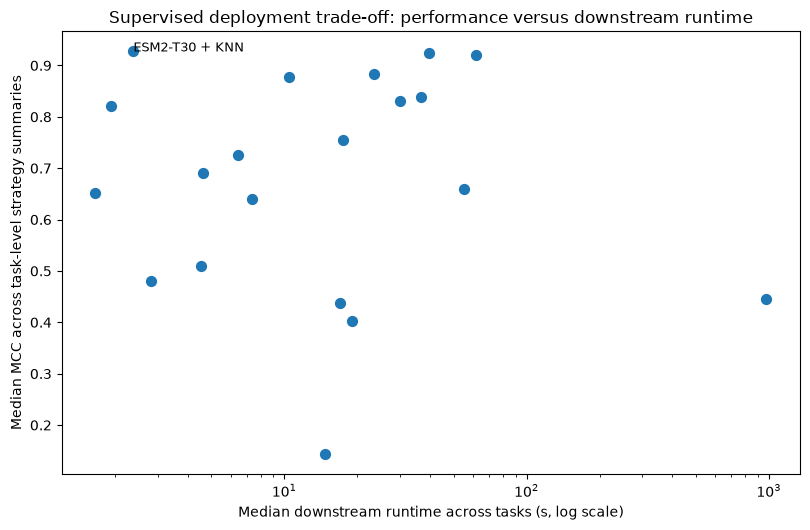

In [10]:
plot_global = global_strategy.copy()

fig, ax = plt.subplots(figsize=(8.2, 5.4))
ax.scatter(
    plot_global["median_runtime_s"],
    plot_global["median_mcc"],
    s=50,
)

highlight = {
    global_performance["strategy"],
    global_efficient["strategy"],
}

for row in plot_global.itertuples(index=False):
    if row.strategy in highlight:
        ax.annotate(
            row.strategy,
            (row.median_runtime_s, row.median_mcc),
            fontsize=9,
        )

ax.set_xscale("log")
ax.set_xlabel("Median downstream runtime across tasks (s, log scale)")
ax.set_ylabel("Median MCC across task-level strategy summaries")
ax.set_title("Supervised deployment trade-off: performance versus downstream runtime")
plt.tight_layout()
plt.show()

# Part II — Final generalization-regime map

RQ9 already established that tasks should be represented by **multi-axis fingerprints**, not forced into one exclusive cluster. RQ20 retains those continuous fingerprints and adds the two validation layers that were not available to RQ9:

- RQ17 finite-test uncertainty;
- common-entity S/R sensitivity.

This prevents RQ20 from turning a descriptive regime label into a stronger claim than the evidence supports.

## 10. Native extreme R and S effects

In [11]:
def extreme_effects(df, axis):
    if axis == "R":
        index_cols = ["task", "representation", "algorithm", "S"]
        level_col = "R"
    elif axis == "S":
        index_cols = ["task", "representation", "algorithm", "R"]
        level_col = "S"
    else:
        raise ValueError(axis)

    wide = (
        df.pivot_table(
            index=index_cols,
            columns=level_col,
            values="mcc",
            aggfunc="first",
        )
        .reset_index()
    )

    if 90 not in wide.columns or 30 not in wide.columns:
        raise RuntimeError(f"Missing 90/30 levels for {axis}")

    wide[f"delta_{axis}30_minus_{axis}90"] = wide[30] - wide[90]
    return wide

native_r = extreme_effects(sup, "R")
native_s = extreme_effects(sup, "S")

native_effect_summary = pd.DataFrame([
    {
        "axis": "R",
        "n": len(native_r),
        "median_delta_30_minus_90": native_r["delta_R30_minus_R90"].median(),
        "median_abs_delta": native_r["delta_R30_minus_R90"].abs().median(),
        "fraction_negative": (native_r["delta_R30_minus_R90"] < 0).mean(),
    },
    {
        "axis": "S",
        "n": len(native_s),
        "median_delta_30_minus_90": native_s["delta_S30_minus_S90"].median(),
        "median_abs_delta": native_s["delta_S30_minus_S90"].abs().median(),
        "fraction_negative": (native_s["delta_S30_minus_S90"] < 0).mean(),
    },
])

display(native_effect_summary)

,axis,n,median_delta_30_minus_90,median_abs_delta,fraction_negative
0,R,560,-0.070347,0.080191,0.821429
1,S,560,-0.016742,0.022797,0.708929


## 11. Merge RQ9 fingerprints with RQ17 finite-test evidence

In [12]:
def subset_contrast(df, *tokens):
    out = df[contrast_contains(df, *tokens)].copy()
    return out

t30_t6_unc = subset_contrast(rep_unc, "t30", "t6")
t30_roxy_unc = subset_contrast(rep_unc, "t30", "roxy")

if t30_t6_unc["task"].nunique() != len(TASK_ORDER):
    raise RuntimeError(
        "Could not resolve one RQ17 T30-vs-T6 uncertainty row per supervised task."
    )

if t30_roxy_unc["task"].nunique() != len(TASK_ORDER):
    raise RuntimeError(
        "Could not resolve one RQ17 T30-vs-Roxy uncertainty row per supervised task."
    )

cap = t30_t6_unc[
    [
        "task", "median_point_delta", "median_ci_width",
        "fraction_resolved_positive", "fraction_overlaps_zero",
    ]
].rename(columns={
    "median_point_delta": "T30_T6_boot_median_delta",
    "median_ci_width": "T30_T6_boot_median_ci_width",
    "fraction_resolved_positive": "T30_T6_fraction_resolved_positive",
    "fraction_overlaps_zero": "T30_T6_fraction_overlaps_zero",
})

roxy_boot = t30_roxy_unc[
    [
        "task", "median_point_delta",
        "fraction_resolved_positive", "fraction_overlaps_zero",
    ]
].rename(columns={
    "median_point_delta": "T30_Roxy_boot_median_delta",
    "fraction_resolved_positive": "T30_Roxy_fraction_resolved_positive",
    "fraction_overlaps_zero": "T30_Roxy_fraction_overlaps_zero",
})

s90 = (
    common_s_unc[common_s_unc["R"].eq(90)]
    [
        [
            "task", "median_point_delta",
            "fraction_resolved_negative", "fraction_overlaps_zero",
            "median_ci_width",
        ]
    ]
    .rename(columns={
        "median_point_delta": "common_S30_minus_S90_at_R90",
        "fraction_resolved_negative": "common_S_at_R90_fraction_resolved_negative",
        "fraction_overlaps_zero": "common_S_at_R90_fraction_overlaps_zero",
        "median_ci_width": "common_S_at_R90_median_ci_width",
    })
)

s30 = (
    common_s_unc[common_s_unc["R"].eq(30)]
    [
        [
            "task", "median_point_delta",
            "fraction_resolved_negative", "fraction_overlaps_zero",
            "median_ci_width",
        ]
    ]
    .rename(columns={
        "median_point_delta": "common_S30_minus_S90_at_R30",
        "fraction_resolved_negative": "common_S_at_R30_fraction_resolved_negative",
        "fraction_overlaps_zero": "common_S_at_R30_fraction_overlaps_zero",
        "median_ci_width": "common_S_at_R30_median_ci_width",
    })
)

regime = (
    rq9.merge(cap, on="task", how="left", validate="one_to_one")
    .merge(roxy_boot, on="task", how="left", validate="one_to_one")
    .merge(s90, on="task", how="left", validate="one_to_one")
    .merge(s30, on="task", how="left", validate="one_to_one")
)

# Explicit VAL finite-test summary.
val_mcc = val_unc[val_unc["metric"].astype(str).str.lower().eq("mcc")].copy()
val_guard = {
    "VAL_median_MCC_CI_width": (
        float(val_mcc["median_ci_width"].median())
        if len(val_mcc) else np.nan
    ),
    "VAL_median_positive_support": (
        float(val_mcc["median_n_positive"].median())
        if len(val_mcc) else np.nan
    ),
    "VAL_min_positive_support": (
        float(val_mcc["min_n_positive"].min())
        if len(val_mcc) and "min_n_positive" in val_mcc.columns
        else np.nan
    ),
}

for key, value in val_guard.items():
    regime[key] = np.nan
    regime.loc[regime["task"].eq("subtype_val"), key] = value

regime["task_label"] = regime["task"].map(TASK_LABELS)

display(
    regime[
        [
            "task", "regime_signature",
            "overall_mcc", "strict_mcc", "worst_mcc",
            "R_signed", "S_signed", "RxS_interaction",
            "T30_minus_T6", "representation_range", "algorithm_range",
            "T30_T6_fraction_resolved_positive",
            "T30_Roxy_fraction_resolved_positive",
            "common_S30_minus_S90_at_R90",
            "common_S_at_R90_fraction_resolved_negative",
            "common_S30_minus_S90_at_R30",
            "common_S_at_R30_fraction_resolved_negative",
            "VAL_median_MCC_CI_width",
            "VAL_median_positive_support",
        ]
    ]
)

,task,regime_signature,overall_mcc,strict_mcc,worst_mcc,R_signed,S_signed,RxS_interaction,T30_minus_T6,representation_range,algorithm_range,T30_T6_fraction_resolved_positive,T30_Roxy_fraction_resolved_positive,common_S30_minus_S90_at_R90,common_S_at_R90_fraction_resolved_negative,common_S30_minus_S90_at_R30,common_S_at_R30_fraction_resolved_negative,VAL_median_MCC_CI_width,VAL_median_positive_support
0,global_easy,"R-sensitive, capacity-sensitive, representatio...",0.715267,0.664537,0.636519,-0.102103,-0.017895,0.047088,0.113017,0.469211,0.130938,1.00,1.00,-0.067844,0.90,-0.012790,0.05,NaN,NaN
1,global_hard,high-floor,0.896734,0.873673,0.846195,-0.045614,-0.007104,0.021067,0.007816,0.170932,0.032686,0.05,1.00,-0.017273,0.45,0.006467,0.10,NaN,NaN
2,global_mixed,"R-sensitive, capacity-sensitive, representatio...",0.721355,0.648663,0.643778,-0.103402,-0.023472,0.010090,0.104026,0.477438,0.163594,1.00,1.00,-0.033528,0.75,0.001670,0.00,NaN,NaN
3,subtype_endolysin,"R-sensitive, interaction-driven, capacity-sens...",0.697403,0.590197,0.555640,-0.142878,-0.019415,0.080343,0.133600,0.510824,0.171483,1.00,1.00,-0.065406,0.90,0.009215,0.00,NaN,NaN
4,subtype_depolymerase,"high-floor, interaction-driven, representation...",0.840849,0.849102,0.792688,0.018144,-0.007922,0.061084,0.021048,0.315777,0.194434,0.30,0.90,-0.052302,0.20,0.009719,0.00,NaN,NaN
5,subtype_val,"evidence-limited, R-sensitive, S-sensitive, in...",0.483795,0.406358,0.193064,-0.044254,-0.035334,0.339206,0.121127,0.706560,0.322258,0.40,0.75,-0.059964,0.10,0.000000,0.00,0.302922,17.0
6,multiclass_clean,representation-sensitive,0.811130,0.820753,0.741285,-0.022622,-0.019777,0.028747,0.030146,0.240024,0.082071,0.35,1.00,-0.039842,0.05,-0.000023,0.00,NaN,NaN


## 12. Visual audit — task-level R and S sensitivity

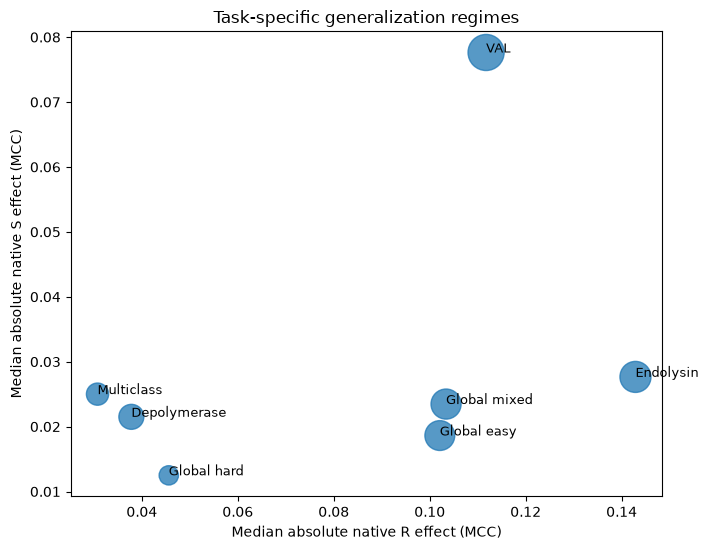

Marker area is proportional to RQ9 representation dependence. R and S remain mechanistically distinct axes; proximity in this plot does not imply causal equivalence.


In [13]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))

sizes = (
    40
    + 900
    * regime["representation_range"]
    .fillna(0)
    .clip(lower=0)
)

ax.scatter(
    regime["R_abs"],
    regime["S_abs"],
    s=sizes,
    alpha=0.75,
)

for row in regime.itertuples(index=False):
    ax.annotate(
        row.task_label,
        (row.R_abs, row.S_abs),
        fontsize=9,
    )

ax.set_xlabel("Median absolute native R effect (MCC)")
ax.set_ylabel("Median absolute native S effect (MCC)")
ax.set_title("Task-specific generalization regimes")
plt.tight_layout()
plt.show()

print(
    "Marker area is proportional to RQ9 representation dependence. "
    "R and S remain mechanistically distinct axes; proximity in this plot "
    "does not imply causal equivalence."
)

## 13. Common-entity S attenuation across R

,R,median_common_S_delta,median_fraction_resolved_negative,median_fraction_overlaps_zero
0,90,-0.052302,0.45,0.55
1,70,-0.025331,0.20,0.65
2,50,-0.008053,0.05,0.90
3,30,0.001670,0.00,0.90


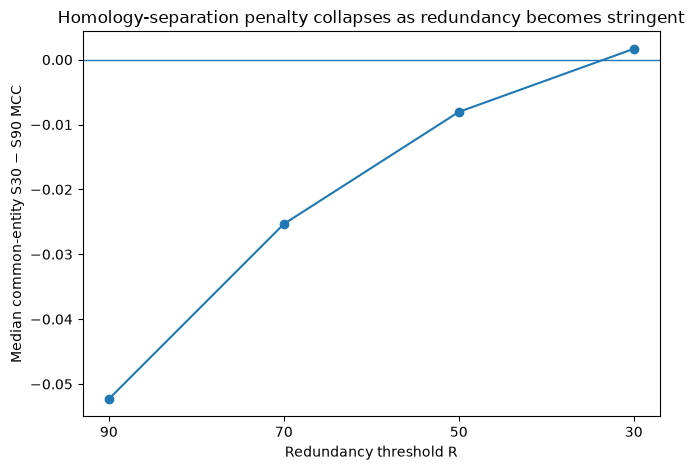

In [14]:
s_by_R = (
    common_s_unc.groupby("R", as_index=False)
    .agg(
        median_common_S_delta=("median_point_delta", "median"),
        median_fraction_resolved_negative=(
            "fraction_resolved_negative", "median"
        ),
        median_fraction_overlaps_zero=(
            "fraction_overlaps_zero", "median"
        ),
    )
    .set_index("R")
    .reindex(R_LEVELS)
    .reset_index()
)

display(s_by_R)

fig, ax = plt.subplots(figsize=(6.8, 4.8))
ax.plot(
    s_by_R["R"].astype(str),
    s_by_R["median_common_S_delta"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median common-entity S30 − S90 MCC")
ax.set_title("Homology-separation penalty collapses as redundancy becomes stringent")
plt.tight_layout()
plt.show()

The same-entity S trajectory is the strongest sensitivity check for the interpretation of S. By contrast, common-R is retained only as a secondary diagnostic because R changes the available biological/evidence universe.

## 14. Secondary common-R sensitivity

In [15]:
common_r_summary = pd.DataFrame([
    {
        "n_S_levels": common_r_unc["S"].nunique(),
        "median_common_R_delta": common_r_unc["median_point_delta"].median(),
        "median_abs_common_R_delta": common_r_unc["median_point_delta"].abs().median(),
        "median_fraction_overlaps_zero": common_r_unc["fraction_overlaps_zero"].median(),
        "median_ci_width": common_r_unc["median_ci_width"].median(),
    }
])

display(common_r_summary)

,n_S_levels,median_common_R_delta,median_abs_common_R_delta,median_fraction_overlaps_zero,median_ci_width
0,4,-0.002876,0.004139,0.9,0.074108


## 15. Representation versus learner uncertainty

In [16]:
def aggregate_uncertainty(df):
    if not len(df):
        return {
            "n": 0,
            "median_point_delta": np.nan,
            "fraction_resolved_positive": np.nan,
            "fraction_resolved_negative": np.nan,
            "fraction_overlaps_zero": np.nan,
        }

    return {
        "n": int(df["n"].sum()),
        "median_point_delta": float(df["median_point_delta"].median()),
        "fraction_resolved_positive": weighted_mean(
            df["fraction_resolved_positive"], df["n"]
        ),
        "fraction_resolved_negative": weighted_mean(
            df["fraction_resolved_negative"], df["n"]
        ),
        "fraction_overlaps_zero": weighted_mean(
            df["fraction_overlaps_zero"], df["n"]
        ),
    }

mlp_lr_unc = subset_contrast(alg_unc, "mlp", "lr")
mlp_xgb_unc = subset_contrast(alg_unc, "mlp", "xgb")

uncertainty_hierarchy = pd.DataFrame([
    {"contrast_family": "T30 − T6", **aggregate_uncertainty(t30_t6_unc)},
    {"contrast_family": "T30 − Roxy", **aggregate_uncertainty(t30_roxy_unc)},
    {"contrast_family": "MLP − LR within T30", **aggregate_uncertainty(mlp_lr_unc)},
    {"contrast_family": "MLP − XGB within T30", **aggregate_uncertainty(mlp_xgb_unc)},
])

display(uncertainty_hierarchy)

,contrast_family,n,median_point_delta,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero
0,T30 − T6,140,0.100210,0.585714,0.0,0.414286
1,T30 − Roxy,140,0.241233,0.950000,0.0,0.042857
2,MLP − LR within T30,28,0.034158,0.571429,0.0,0.428571
3,MLP − XGB within T30,28,0.004193,0.107143,0.0,0.892857


# Part III — PU deployment regimes

RQ20 keeps **recognition** and **discovery** separate.

For known-positive recovery, the relevant evidence is U95 recovery and its paired finite-test uncertainty.

For discovery, the relevant evidence is whether alternative paradigms reorganize the U ranking. A method can therefore be unnecessary for recovery yet consequential for candidate nomination.

No PU runtime comparison is made because RQ18 established that usable retained PU wall-time instrumentation is absent.

## 16. PU strategy profiles

In [17]:
pu_strategy = (
    pu_native.groupby(
        ["task", "representation", "method", "algorithm"],
        as_index=False,
    )
    .agg(
        n_rs_cells=("fraction_P_above_U95", "size"),
        median_U95=("fraction_P_above_U95", "median"),
        q25_U95=("fraction_P_above_U95", lambda x: x.quantile(0.25)),
        worst_U95=("fraction_P_above_U95", "min"),
        median_P_percentile=("median_P_percentile_vs_U", "median"),
    )
)

display(
    pu_strategy.sort_values(
        ["task", "median_U95"],
        ascending=[True, False],
    )
)

,task,representation,method,algorithm,n_rs_cells,median_U95,q25_U95,worst_U95,median_P_percentile
3,pu_broad,esm2_t30_150m,elkan_noto,XGB,16,0.930966,0.907649,0.883910,1.000000
5,pu_broad,esm2_t30_150m,naive,XGB,16,0.930966,0.907649,0.883910,0.999017
1,pu_broad,esm2_t30_150m,baggingpu,XGB,16,0.928636,0.902802,0.881874,0.998171
0,pu_broad,esm2_t30_150m,baggingpu,LR,16,0.920592,0.884641,0.869295,0.997938
2,pu_broad,esm2_t30_150m,elkan_noto,LR,16,0.914206,0.878520,0.848548,1.000000
4,pu_broad,esm2_t30_150m,naive,LR,16,0.914206,0.878520,0.848548,0.997671
9,pu_broad,esm2_t6_8m,elkan_noto,XGB,16,0.858666,0.827670,0.792261,1.000000
11,pu_broad,esm2_t6_8m,naive,XGB,16,0.858666,0.827670,0.792261,0.996752
7,pu_broad,esm2_t6_8m,baggingpu,XGB,16,0.848049,0.812906,0.778004,0.995788
6,pu_broad,esm2_t6_8m,baggingpu,LR,16,0.825011,0.791861,0.755601,0.993454


## 17. PU recovery uncertainty and discovery-space divergence

In [18]:
pu_method_view = pu_method_unc.copy()

bag_unc = pu_method_view[
    contrast_contains(pu_method_view, "bagging", "naive")
].copy()

en_unc = pu_method_view[
    contrast_contains(pu_method_view, "elkan", "naive")
    | contrast_contains(pu_method_view, "noto", "naive")
].copy()

if bag_unc["representation"].nunique() != 4:
    raise RuntimeError(
        "Could not resolve BaggingPU-vs-naive uncertainty for all four representations."
    )

# RQ15 evidence rows contain the matching discovery diagnostics.
rq15_view = rq15_evidence.copy()

display(
    rq15_view[
        [
            "method", "representation",
            "median_U95_gain_vs_naive",
            "fraction_U95_practical_tie",
            "median_method_pair_U_spearman",
            "median_fixed_top1_jaccard",
            "median_fixed_top5_jaccard",
        ]
    ].sort_values(["method", "representation"])
)

display(
    bag_unc[
        [
            "representation", "median_point_delta",
            "fraction_resolved_positive",
            "fraction_resolved_negative",
            "fraction_overlaps_zero",
        ]
    ]
)

,method,representation,median_U95_gain_vs_naive,fraction_U95_practical_tie,median_method_pair_U_spearman,median_fixed_top1_jaccard,median_fixed_top5_jaccard
3,baggingpu,esm2_t30_150m,0.000344,0.953125,0.807569,0.657416,0.529634
2,baggingpu,esm2_t6_8m,-0.002757,0.875000,0.907626,0.675854,0.700646
1,baggingpu,onehot_1024,0.093082,0.265625,0.668640,0.329825,0.410044
0,baggingpu,roxy_48,0.000000,0.953125,0.967496,0.753912,0.811643
7,elkan_noto,esm2_t30_150m,0.000000,1.000000,1.000000,1.000000,1.000000
6,elkan_noto,esm2_t6_8m,0.000000,1.000000,0.999999,0.790698,1.000000
5,elkan_noto,onehot_1024,0.000000,0.750000,0.999958,0.121187,1.000000
4,elkan_noto,roxy_48,0.000000,0.750000,0.999982,0.201910,1.000000


,representation,median_point_delta,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero
0,esm2_t30_150m,0.000344,0.171875,0.125000,0.703125
1,esm2_t6_8m,-0.002757,0.062500,0.187500,0.750000
2,onehot_1024,0.093082,0.593750,0.031250,0.375000
3,roxy_48,0.000000,0.031250,0.015625,0.953125


## 18. Scenario-specific PU deployment map

In [19]:
def get_unique(df, mask, context):
    g = df[mask].copy()
    if len(g) != 1:
        raise RuntimeError(
            f"Expected one row for {context}; observed {len(g)}."
        )
    return g.iloc[0]

bag_t30 = get_unique(
    bag_unc,
    bag_unc["representation"].astype(str).eq(T30),
    "T30 BaggingPU-vs-naive uncertainty",
)

bag_onehot = get_unique(
    bag_unc,
    bag_unc["representation"].astype(str).eq(ONEHOT),
    "one-hot BaggingPU-vs-naive uncertainty",
)

t30_discovery = get_unique(
    rq15_view,
    rq15_view["method"].astype(str).eq("baggingpu")
    & rq15_view["representation"].astype(str).eq(T30),
    "T30 BaggingPU discovery evidence",
)

# Recovery default:
# If BaggingPU is more often directionally resolved positive than unresolved,
# it becomes the dedicated recovery choice. Otherwise retain naive as the
# simpler modeling assumption. This uses no runtime claim.
t30_recovery_paradigm = (
    "baggingpu"
    if float(bag_t30["fraction_resolved_positive"])
       > float(bag_t30["fraction_overlaps_zero"])
    else "naive"
)

onehot_recovery_paradigm = (
    "baggingpu"
    if float(bag_onehot["fraction_resolved_positive"])
       > float(bag_onehot["fraction_overlaps_zero"])
    else "naive"
)

pu_deployment = pd.DataFrame([
    {
        "domain": "PU",
        "scenario": "known_positive_recovery",
        "recommended_representation": T30,
        "recommended_paradigm": t30_recovery_paradigm,
        "companion_strategy": (
            "BaggingPU remains optional sensitivity analysis."
            if t30_recovery_paradigm == "naive"
            else "Naive P-vs-U remains the matched baseline."
        ),
        "evidence": (
            f"T30 BaggingPU−naive median ΔU95={bag_t30['median_point_delta']:.4f}; "
            f"resolved-positive fraction={bag_t30['fraction_resolved_positive']:.3f}; "
            f"overlap-zero fraction={bag_t30['fraction_overlaps_zero']:.3f}."
        ),
        "guardrail": (
            "This recommendation concerns recovery of labeled positives, not discovery ranking. "
            "No PU runtime advantage is claimed."
        ),
    },
    {
        "domain": "PU",
        "scenario": "candidate_discovery",
        "recommended_representation": T30,
        "recommended_paradigm": "naive + baggingpu consensus",
        "companion_strategy": "Use broad U and retain paradigm disagreement as discovery information.",
        "evidence": (
            f"Naive/BaggingPU U-score Spearman under T30="
            f"{t30_discovery['median_method_pair_U_spearman']:.3f}; "
            f"fixed top-5% Jaccard={t30_discovery['median_fixed_top5_jaccard']:.3f}."
        ),
        "guardrail": (
            "Candidate reordering is meaningful even when known-positive recovery changes little. "
            "U remains unlabeled."
        ),
    },
    {
        "domain": "PU",
        "scenario": "legacy_weak_representation_recovery",
        "recommended_representation": ONEHOT,
        "recommended_paradigm": onehot_recovery_paradigm,
        "companion_strategy": "Prefer upgrading the representation when feasible.",
        "evidence": (
            f"One-hot BaggingPU−naive median ΔU95={bag_onehot['median_point_delta']:.4f}; "
            f"resolved-positive fraction={bag_onehot['fraction_resolved_positive']:.3f}; "
            f"overlap-zero fraction={bag_onehot['fraction_overlaps_zero']:.3f}."
        ),
        "guardrail": (
            "The one-hot PU-sensitive regime does not imply that one-hot is a competitive "
            "representation overall."
        ),
    },
    {
        "domain": "PU",
        "scenario": "score_correction_diagnostic",
        "recommended_representation": T30,
        "recommended_paradigm": "elkan_noto diagnostic only",
        "companion_strategy": "Do not use EN U99 ceiling behavior as a discovery advantage.",
        "evidence": "RQ12/RQ15 show largely rank-preserving correction with clipping/tie sensitivity.",
        "guardrail": "Upper-tail clipping can inflate tie-inclusive U99 diagnostics.",
    },
])

display(pu_deployment)

,domain,scenario,recommended_representation,recommended_paradigm,companion_strategy,evidence,guardrail
0,PU,known_positive_recovery,esm2_t30_150m,naive,BaggingPU remains optional sensitivity analysis.,T30 BaggingPU−naive median ΔU95=0.0003; resolv...,This recommendation concerns recovery of label...
1,PU,candidate_discovery,esm2_t30_150m,naive + baggingpu consensus,Use broad U and retain paradigm disagreement a...,Naive/BaggingPU U-score Spearman under T30=0.8...,Candidate reordering is meaningful even when k...
2,PU,legacy_weak_representation_recovery,onehot_1024,baggingpu,Prefer upgrading the representation when feasi...,One-hot BaggingPU−naive median ΔU95=0.0931; re...,The one-hot PU-sensitive regime does not imply...
3,PU,score_correction_diagnostic,esm2_t30_150m,elkan_noto diagnostic only,Do not use EN U99 ceiling behavior as a discov...,RQ12/RQ15 show largely rank-preserving correct...,Upper-tail clipping can inflate tie-inclusive ...


## 19. T30 representation advantage across PU paradigms

In [20]:
display(pu_rep_unc)

if not pu_rep_unc["fraction_resolved_positive"].ge(0).all():
    raise RuntimeError("Invalid PU representation uncertainty fractions.")

pu_rep_global = {
    "median_T30_minus_T6_U95": float(pu_rep_unc["median_point_delta"].median()),
    "min_fraction_resolved_positive": float(
        pu_rep_unc["fraction_resolved_positive"].min()
    ),
    "max_fraction_overlaps_zero": float(
        pu_rep_unc["fraction_overlaps_zero"].max()
    ),
}

print(pu_rep_global)

,method,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,baggingpu,64,0.075929,0.042323,1.0,0.0,0.0,1.0
1,elkan_noto,64,0.072383,0.043146,1.0,0.0,0.0,1.0
2,naive,64,0.072383,0.041958,1.0,0.0,0.0,1.0


{'median_T30_minus_T6_U95': 0.0723826120017743, 'min_fraction_resolved_positive': 1.0, 'max_fraction_overlaps_zero': 0.0}


# Part IV — Candidate-readiness bridge

RQ20 does **not** rerank candidates. It only records whether the final modeling strategy already produces an actionable experimental shortlist and carries forward the RQ19 guardrails.

## 20. RQ19 candidate-readiness summary

In [21]:
if len(rq19_summary) != 1:
    raise RuntimeError(
        f"Expected one-row RQ19 final summary; observed {len(rq19_summary)}."
    )

candidate_readiness = rq19_summary.copy()
candidate_readiness["interpretation"] = (
    "Predictive consensus nominates candidates; R/S breadth, Roxy support, "
    "T30 latent support, and sequence novelty characterize them independently."
)
candidate_readiness["deployment_status"] = (
    "ready_for_experimental_prioritization"
)
candidate_readiness["guardrail"] = (
    "No calibrated biological probability, mechanistic validation, or "
    "computational proof of lytic function is implied."
)

display(candidate_readiness)

,eligible_candidates,top20_min_predictive_core,top20_median_predictive_core,top20_median_q25_percentile,top20_fraction_top5_every_observation,top20_fraction_both_R30_S30_observed,top20_median_rs_cells,top20_median_roxy_support,top20_median_T30_latent_support,top20_median_sequence_novelty,top20_exact_P_identity_fraction,strict_axis_supported_top20_n,interpretation,deployment_status,guardrail
0,101370,0.999225,0.999626,0.999431,1.0,0.7,5.0,0.599448,0.719286,0.437517,0.0,14,Predictive consensus nominates candidates; R/S...,ready_for_experimental_prioritization,"No calibrated biological probability, mechanis..."


# Part V — Observed generalization-regime catalogue

The roadmap proposed several possible regimes, but explicitly required that they **not be imposed a priori**.

RQ20 therefore records only regimes supported by the completed analyses, with qualification where necessary.

## 21. Quantitative backbone for the final regime catalogue

In [22]:
# Matched representation effects directly from the frozen supervised master.
rep_wide = (
    sup.pivot_table(
        index=["task", "R", "S", "algorithm"],
        columns="representation",
        values="mcc",
        aggfunc="first",
    )
    .reset_index()
)

rep_native = {
    "T30_minus_T6": float((rep_wide[T30] - rep_wide[T6]).median()),
    "T30_minus_Roxy": float((rep_wide[T30] - rep_wide[ROXY]).median()),
    "T30_minus_onehot": float((rep_wide[T30] - rep_wide[ONEHOT]).median()),
}

# Learner effects restricted to T30.
t30_sup = sup[sup["representation"].eq(T30)]
alg_wide = (
    t30_sup.pivot_table(
        index=["task", "R", "S"],
        columns="algorithm",
        values="mcc",
        aggfunc="first",
    )
    .reset_index()
)

alg_native = {
    "MLP_minus_LR": float((alg_wide["MLP"] - alg_wide["LR"]).median()),
    "MLP_minus_XGB": float((alg_wide["MLP"] - alg_wide["XGB"]).median()),
}

global_hard_capacity = float(
    rq9.loc[
        rq9["task"].eq("global_hard"),
        "T30_minus_T6",
    ].iloc[0]
)

val_row = regime[regime["task"].eq("subtype_val")].iloc[0]

quant_backbone = pd.DataFrame([
    {
        "evidence_family": "native_R",
        "value": native_effect_summary.loc[
            native_effect_summary["axis"].eq("R"),
            "median_delta_30_minus_90",
        ].iloc[0],
    },
    {
        "evidence_family": "native_S",
        "value": native_effect_summary.loc[
            native_effect_summary["axis"].eq("S"),
            "median_delta_30_minus_90",
        ].iloc[0],
    },
    {
        "evidence_family": "common_R_T30",
        "value": common_r_summary["median_common_R_delta"].iloc[0],
    },
    {
        "evidence_family": "common_S_at_R90",
        "value": s_by_R.loc[
            s_by_R["R"].eq(90),
            "median_common_S_delta",
        ].iloc[0],
    },
    {
        "evidence_family": "common_S_at_R30",
        "value": s_by_R.loc[
            s_by_R["R"].eq(30),
            "median_common_S_delta",
        ].iloc[0],
    },
    {
        "evidence_family": "T30_minus_T6",
        "value": rep_native["T30_minus_T6"],
    },
    {
        "evidence_family": "T30_minus_Roxy",
        "value": rep_native["T30_minus_Roxy"],
    },
    {
        "evidence_family": "MLP_minus_XGB_T30",
        "value": alg_native["MLP_minus_XGB"],
    },
])

display(quant_backbone)

,evidence_family,value
0,native_R,-0.070347
1,native_S,-0.016742
2,common_R_T30,-0.002876
3,common_S_at_R90,-0.052302
4,common_S_at_R30,0.001670
5,T30_minus_T6,0.076907
6,T30_minus_Roxy,0.234556
7,MLP_minus_XGB_T30,0.004508


## 22. Final regime catalogue

In [23]:
t30t6_all = aggregate_uncertainty(t30_t6_unc)
t30roxy_all = aggregate_uncertainty(t30_roxy_unc)
mlpxgb_all = aggregate_uncertainty(mlp_xgb_unc)

bag_onehot_ev = get_unique(
    rq15_view,
    rq15_view["method"].astype(str).eq("baggingpu")
    & rq15_view["representation"].astype(str).eq(ONEHOT),
    "one-hot RQ15 BaggingPU evidence",
)

catalogue_rows = [
    {
        "regime": "redundancy/evidence-population sensitive",
        "status": "observed",
        "scope": "supervised benchmark",
        "evidence": (
            f"Native R30−R90 median MCC={native_effect_summary.loc[native_effect_summary.axis.eq('R'),'median_delta_30_minus_90'].iloc[0]:.4f}; "
            f"same-entity T30 common-R median={common_r_summary['median_common_R_delta'].iloc[0]:.4f}."
        ),
        "interpretation": (
            "R is the dominant benchmark-wide perturbation, but much of its native magnitude "
            "reflects restructuring of available evidence/evaluation population in addition to "
            "same-entity generalization difficulty."
        ),
    },
    {
        "regime": "homology-sensitive",
        "status": "observed conditionally",
        "scope": "high-redundancy regimes",
        "evidence": (
            f"Common-entity S30−S90 median at R90="
            f"{s_by_R.loc[s_by_R.R.eq(90),'median_common_S_delta'].iloc[0]:.4f}; "
            f"at R30={s_by_R.loc[s_by_R.R.eq(30),'median_common_S_delta'].iloc[0]:.4f}."
        ),
        "interpretation": (
            "The S penalty persists on the same proteins when redundant support is high, "
            "but collapses as R becomes stringent."
        ),
    },
    {
        "regime": "representation-dependent",
        "status": "observed strongly",
        "scope": "supervised and PU",
        "evidence": (
            f"Supervised median T30−Roxy={rep_native['T30_minus_Roxy']:.4f}; "
            f"RQ17 resolved-positive fraction={t30roxy_all['fraction_resolved_positive']:.3f}. "
            f"PU T30−T6 minimum resolved-positive fraction across paradigms="
            f"{pu_rep_global['min_fraction_resolved_positive']:.3f}."
        ),
        "interpretation": (
            "Representation choice is a major and uncertainty-supported determinant of generalization."
        ),
    },
    {
        "regime": "capacity-dependent",
        "status": "observed but task-dependent",
        "scope": "T30 versus T6",
        "evidence": (
            f"Overall supervised median T30−T6={rep_native['T30_minus_T6']:.4f}; "
            f"resolved-positive fraction={t30t6_all['fraction_resolved_positive']:.3f}; "
            f"global-hard RQ9 T30−T6={global_hard_capacity:.4f}."
        ),
        "interpretation": (
            "Larger PLM capacity helps many tasks, while global-hard provides a clear saturation regime."
        ),
    },
    {
        "regime": "learner-secondary / upper-tier saturation",
        "status": "observed",
        "scope": "T30 downstream learners",
        "evidence": (
            f"Median MLP−XGB={alg_native['MLP_minus_XGB']:.4f}; "
            f"RQ17 overlap-zero fraction={mlpxgb_all['fraction_overlaps_zero']:.3f}."
        ),
        "interpretation": (
            "Among competitive learners, downstream classifier differences are usually smaller "
            "than representation effects and often unresolved against finite-test uncertainty."
        ),
    },
    {
        "regime": "label-uncertain / discovery-coupled",
        "status": "observed",
        "scope": "PU",
        "evidence": (
            f"One-hot BaggingPU median ΔU95={bag_onehot['median_point_delta']:.4f}; "
            f"T30 naive/BaggingPU U-score Spearman="
            f"{t30_discovery['median_method_pair_U_spearman']:.3f}."
        ),
        "interpretation": (
            "Dedicated PU learning has representation-specific recovery value and can materially "
            "reorganize candidate discovery even where recovery gains are small."
        ),
    },
    {
        "regime": "evidence-limited",
        "status": "observed",
        "scope": "VAL",
        "evidence": (
            f"VAL median MCC CI width={val_guard['VAL_median_MCC_CI_width']:.4f}; "
            f"median positive outer-test support={val_guard['VAL_median_positive_support']:.1f}."
        ),
        "interpretation": (
            "Evidence scarcity limits both learning and precision of performance estimation; "
            "standalone high-confidence deployment is not supported."
        ),
    },
    {
        "regime": "formulation-dependent",
        "status": (
            "observed"
            if len(rq11_regime)
            else "supported upstream; optional cache unavailable"
        ),
        "scope": "binary versus multiclass",
        "evidence": (
            "RQ11 shows that subtype recognition and multiclass discrimination can occupy "
            "different generalization regimes for the same named biological class."
        ),
        "interpretation": (
            "The benchmark is defined by the decision problem as well as the label name."
        ),
    },
]

regime_catalogue = pd.DataFrame(catalogue_rows)
display(regime_catalogue)

,regime,status,scope,evidence,interpretation
0,redundancy/evidence-population sensitive,observed,supervised benchmark,Native R30−R90 median MCC=-0.0703; same-entity...,"R is the dominant benchmark-wide perturbation,..."
1,homology-sensitive,observed conditionally,high-redundancy regimes,Common-entity S30−S90 median at R90=-0.0523; a...,The S penalty persists on the same proteins wh...
2,representation-dependent,observed strongly,supervised and PU,Supervised median T30−Roxy=0.2346; RQ17 resolv...,Representation choice is a major and uncertain...
3,capacity-dependent,observed but task-dependent,T30 versus T6,Overall supervised median T30−T6=0.0769; resol...,"Larger PLM capacity helps many tasks, while gl..."
4,learner-secondary / upper-tier saturation,observed,T30 downstream learners,Median MLP−XGB=0.0045; RQ17 overlap-zero fract...,"Among competitive learners, downstream classif..."
5,label-uncertain / discovery-coupled,observed,PU,One-hot BaggingPU median ΔU95=0.0931; T30 naiv...,Dedicated PU learning has representation-speci...
6,evidence-limited,observed,VAL,VAL median MCC CI width=0.3029; median positiv...,Evidence scarcity limits both learning and pre...
7,formulation-dependent,observed,binary versus multiclass,RQ11 shows that subtype recognition and multic...,The benchmark is defined by the decision probl...


# Part VI — Final deployment decision map

This table is the practical endpoint of RQ20.

It does not say “model X is best.” It says:

> **for objective Y, under constraint Z, strategy X is the benchmark-supported default/reference, with explicit alternatives and guardrails.**

## 23. Assemble final deployment map

In [24]:
final_rows = []

# Task-specific supervised rows.
for row in supervised_deployment.itertuples(index=False):
    final_rows.append({
        "scenario": f"supervised::{row.objective}",
        "scope": row.task,
        "recommended_strategy": row.strategy,
        "alternative_or_companion": (
            "Consult the other task-specific objective rows when deployment priorities differ."
        ),
        "primary_evidence": (
            f"median_MCC={row.median_mcc:.4f}; "
            f"worst_MCC={row.worst_mcc:.4f}; "
            f"S30_median={row.S30_median_mcc:.4f}; "
            f"R30S30={row.joint_strict_R30_S30_mcc:.4f}; "
            f"Pareto_rate={row.pareto_rate:.3f}; "
            f"near_best_rate={row.near_best_rate:.3f}; "
            f"runtime={row.median_downstream_runtime_s:.2f}s."
        ),
        "guardrail": row.guardrail,
    })

# Cross-task references.
final_rows.append({
    "scenario": "supervised::cross_task_performance_reference",
    "scope": "all supervised tasks",
    "recommended_strategy": global_performance["strategy"],
    "alternative_or_companion": global_efficient["strategy"],
    "primary_evidence": (
        f"Cross-task median MCC={global_performance['median_mcc']:.4f}; "
        f"median worst-case MCC={global_performance['median_worst_mcc']:.4f}."
    ),
    "guardrail": (
        "Reference only; task-specific regimes override a universal default."
    ),
})

final_rows.append({
    "scenario": "supervised::cross_task_compute_aware_near_best_reference",
    "scope": "all supervised tasks",
    "recommended_strategy": global_efficient["strategy"],
    "alternative_or_companion": global_performance["strategy"],
    "primary_evidence": (
        f"Median Pareto rate={global_efficient['median_pareto_rate']:.3f}; "
        f"median near-best rate={global_efficient['median_near_best_rate']:.3f}; "
        f"median downstream runtime={global_efficient['median_runtime_s']:.2f}s."
    ),
    "guardrail": (
        "Downstream runtime excludes the one-time representation extraction cost."
    ),
})

# PU rows.
for row in pu_deployment.itertuples(index=False):
    final_rows.append({
        "scenario": f"PU::{row.scenario}",
        "scope": "positive–unlabeled benchmark",
        "recommended_strategy": (
            f"{REP_LABELS.get(row.recommended_representation, row.recommended_representation)} "
            f"+ {row.recommended_paradigm}"
        ),
        "alternative_or_companion": row.companion_strategy,
        "primary_evidence": row.evidence,
        "guardrail": row.guardrail,
    })

# VAL explicit guardrail.
final_rows.append({
    "scenario": "deployment_guardrail::VAL",
    "scope": "subtype_val",
    "recommended_strategy": "No standalone high-confidence deployment",
    "alternative_or_companion": (
        "Use model output as evidence-supporting triage with explicit uncertainty "
        "and prioritize additional labeled evidence."
    ),
    "primary_evidence": (
        f"Median finite-test MCC CI width={val_guard['VAL_median_MCC_CI_width']:.4f}; "
        f"median positive support={val_guard['VAL_median_positive_support']:.1f}."
    ),
    "guardrail": (
        "High point estimates in individual cells do not remove the Low-N limitation."
    ),
})

# Candidate follow-up.
rq19_row = rq19_summary.iloc[0]
final_rows.append({
    "scenario": "discovery::experimental_follow_up",
    "scope": "broad-U candidate universe",
    "recommended_strategy": (
        "RQ19 predictive consensus shortlist + independent R/S/Roxy/T30/novelty characterization"
    ),
    "alternative_or_companion": (
        "Experimental validation; no additional scalar reranking in RQ20."
    ),
    "primary_evidence": (
        f"Eligible candidates={int(rq19_row['eligible_candidates'])}; "
        f"top20 median predictive core={rq19_row['top20_median_predictive_core']:.6f}; "
        f"strict-axis-supported top20 n={int(rq19_row['strict_axis_supported_top20_n'])}; "
        f"exact-P identity fraction={rq19_row['top20_exact_P_identity_fraction']:.3f}."
    ),
    "guardrail": (
        "Prioritized for experimental characterization; not computationally validated function."
    ),
})

final_deployment_map = pd.DataFrame(final_rows)

display(final_deployment_map)

,scenario,scope,recommended_strategy,alternative_or_companion,primary_evidence,guardrail
0,supervised::performance_oriented,global_easy,ESM2-T30 + KNN,Consult the other task-specific objective rows...,median_MCC=0.9377; worst_MCC=0.8837; S30_media...,Observed-best and within-0.02 strategies are d...
1,supervised::remote_homology,global_easy,ESM2-T30 + MLP,Consult the other task-specific objective rows...,median_MCC=0.9362; worst_MCC=0.8695; S30_media...,Observed-best and within-0.02 strategies are d...
2,supervised::joint_strict,global_easy,ESM2-T30 + KNN,Consult the other task-specific objective rows...,median_MCC=0.9377; worst_MCC=0.8837; S30_media...,Observed-best and within-0.02 strategies are d...
3,supervised::compute_aware_near_best,global_easy,ESM2-T30 + KNN,Consult the other task-specific objective rows...,median_MCC=0.9377; worst_MCC=0.8837; S30_media...,Observed-best and within-0.02 strategies are d...
4,supervised::performance_oriented,global_hard,ESM2-T30 + XGB,Consult the other task-specific objective rows...,median_MCC=0.9428; worst_MCC=0.9009; S30_media...,Observed-best and within-0.02 strategies are d...
5,supervised::remote_homology,global_hard,ESM2-T30 + LR,Consult the other task-specific objective rows...,median_MCC=0.9376; worst_MCC=0.8858; S30_media...,Observed-best and within-0.02 strategies are d...
6,supervised::joint_strict,global_hard,ESM2-T30 + RF,Consult the other task-specific objective rows...,median_MCC=0.9405; worst_MCC=0.9153; S30_media...,Observed-best and within-0.02 strategies are d...
7,supervised::compute_aware_near_best,global_hard,ESM2-T6 + KNN,Consult the other task-specific objective rows...,median_MCC=0.9271; worst_MCC=0.8955; S30_media...,Observed-best and within-0.02 strategies are d...
8,supervised::performance_oriented,global_mixed,ESM2-T30 + KNN,Consult the other task-specific objective rows...,median_MCC=0.9272; worst_MCC=0.8736; S30_media...,Observed-best and within-0.02 strategies are d...
9,supervised::remote_homology,global_mixed,ESM2-T30 + MLP,Consult the other task-specific objective rows...,median_MCC=0.9237; worst_MCC=0.8644; S30_media...,Observed-best and within-0.02 strategies are d...


## 24. Compact manuscript-level claims

In [25]:
claims = pd.DataFrame([
    {
        "claim_id": "C1",
        "status": "supported",
        "claim": (
            "Redundancy control and train–test homology separation affect generalization "
            "through distinguishable mechanisms."
        ),
        "qualification": (
            "Native R combines evidence/population restructuring with generalization; "
            "common-S provides the cleaner same-entity sensitivity analysis."
        ),
    },
    {
        "claim_id": "C2",
        "status": "supported",
        "claim": (
            "The S penalty is conditional on redundancy: it is strongest when redundant "
            "support remains high and loses magnitude and directional resolution as R becomes stringent."
        ),
        "qualification": (
            "The exact four-corner common population remains too sparse to make a decisive "
            "same-entity claim about the full R×S interaction."
        ),
    },
    {
        "claim_id": "C3",
        "status": "supported strongly",
        "claim": (
            "Protein representation is a more robust determinant of predictive performance "
            "than the choice among competitive downstream learners."
        ),
        "qualification": (
            f"Native median T30−Roxy={rep_native['T30_minus_Roxy']:.4f}; "
            f"MLP−XGB within T30={alg_native['MLP_minus_XGB']:.4f}."
        ),
    },
    {
        "claim_id": "C4",
        "status": "supported conditionally",
        "claim": (
            "Scaling ESM2 from T6 to T30 produces a real but task-dependent gain, "
            "with saturation in selected regimes such as global-hard."
        ),
        "qualification": (
            "Do not present T30−T6 as a monotonic function of R/S stringency."
        ),
    },
    {
        "claim_id": "C5",
        "status": "supported",
        "claim": (
            "PU learning is recovery-substitutive in strong representations but remains "
            "discovery-coupled because paradigm choice can reorganize the unlabeled candidate tail."
        ),
        "qualification": (
            "One-hot is a distinct PU-sensitive recovery regime; Elkan–Noto remains clipping/tie-sensitive."
        ),
    },
    {
        "claim_id": "C6",
        "status": "supported",
        "claim": (
            "A strong pretrained representation can support simpler downstream deployment "
            "without requiring the most expensive learner in every task."
        ),
        "qualification": (
            f"Cross-task compute-aware near-best reference: {global_efficient['strategy']}; "
            f"performance reference: {global_performance['strategy']}. "
            "Representation extraction cost is amortizable and reported separately."
        ),
    },
    {
        "claim_id": "C7",
        "status": "supported",
        "claim": (
            "VAL is evidence-limited not only for learning but for precise model evaluation."
        ),
        "qualification": (
            "VAL predictions should not be promoted to standalone high-confidence deployment."
        ),
    },
    {
        "claim_id": "C8",
        "status": "supported as demonstration",
        "claim": (
            "The PU benchmark can nominate a robust experimental candidate shortlist while "
            "keeping predictive consensus, generalization breadth, orthogonal support, and novelty separate."
        ),
        "qualification": (
            "Candidate prioritization is not biological validation."
        ),
    },
])

display(claims)

,claim_id,status,claim,qualification
0,C1,supported,Redundancy control and train–test homology sep...,Native R combines evidence/population restruct...
1,C2,supported,The S penalty is conditional on redundancy: it...,The exact four-corner common population remain...
2,C3,supported strongly,Protein representation is a more robust determ...,Native median T30−Roxy=0.2346; MLP−XGB within ...
3,C4,supported conditionally,Scaling ESM2 from T6 to T30 produces a real bu...,Do not present T30−T6 as a monotonic function ...
4,C5,supported,PU learning is recovery-substitutive in strong...,One-hot is a distinct PU-sensitive recovery re...
5,C6,supported,A strong pretrained representation can support...,Cross-task compute-aware near-best reference: ...
6,C7,supported,VAL is evidence-limited not only for learning ...,VAL predictions should not be promoted to stan...
7,C8,supported as demonstration,The PU benchmark can nominate a robust experim...,Candidate prioritization is not biological val...


## 25. Final RQ20 evidence dashboard

In [26]:
dashboard = pd.DataFrame([
    {
        "dimension": "Native R effect",
        "summary": (
            f"median R30−R90 MCC="
            f"{native_effect_summary.loc[native_effect_summary.axis.eq('R'),'median_delta_30_minus_90'].iloc[0]:.4f}"
        ),
    },
    {
        "dimension": "Native S effect",
        "summary": (
            f"median S30−S90 MCC="
            f"{native_effect_summary.loc[native_effect_summary.axis.eq('S'),'median_delta_30_minus_90'].iloc[0]:.4f}"
        ),
    },
    {
        "dimension": "Common S at R90",
        "summary": (
            f"median S30−S90 MCC="
            f"{s_by_R.loc[s_by_R.R.eq(90),'median_common_S_delta'].iloc[0]:.4f}"
        ),
    },
    {
        "dimension": "Common S at R30",
        "summary": (
            f"median S30−S90 MCC="
            f"{s_by_R.loc[s_by_R.R.eq(30),'median_common_S_delta'].iloc[0]:.4f}"
        ),
    },
    {
        "dimension": "T30−Roxy",
        "summary": (
            f"median ΔMCC={rep_native['T30_minus_Roxy']:.4f}; "
            f"resolved-positive={t30roxy_all['fraction_resolved_positive']:.3f}"
        ),
    },
    {
        "dimension": "T30−T6",
        "summary": (
            f"median ΔMCC={rep_native['T30_minus_T6']:.4f}; "
            f"resolved-positive={t30t6_all['fraction_resolved_positive']:.3f}"
        ),
    },
    {
        "dimension": "MLP−XGB within T30",
        "summary": (
            f"median ΔMCC={alg_native['MLP_minus_XGB']:.4f}; "
            f"overlap-zero={mlpxgb_all['fraction_overlaps_zero']:.3f}"
        ),
    },
    {
        "dimension": "PU T30−T6",
        "summary": (
            f"median ΔU95={pu_rep_global['median_T30_minus_T6_U95']:.4f}; "
            f"minimum resolved-positive across paradigms="
            f"{pu_rep_global['min_fraction_resolved_positive']:.3f}"
        ),
    },
    {
        "dimension": "VAL",
        "summary": (
            f"median MCC CI width={val_guard['VAL_median_MCC_CI_width']:.4f}; "
            f"median positive support={val_guard['VAL_median_positive_support']:.1f}"
        ),
    },
    {
        "dimension": "Supervised performance reference",
        "summary": str(global_performance["strategy"]),
    },
    {
        "dimension": "Supervised compute-aware near-best reference",
        "summary": str(global_efficient["strategy"]),
    },
    {
        "dimension": "Candidate readiness",
        "summary": (
            f"{int(rq19_row['strict_axis_supported_top20_n'])}/20 top candidates "
            "have both R30 and S30 observed; experimental validation remains required."
        ),
    },
])

display(dashboard)

,dimension,summary
0,Native R effect,median R30−R90 MCC=-0.0703
1,Native S effect,median S30−S90 MCC=-0.0167
2,Common S at R90,median S30−S90 MCC=-0.0523
3,Common S at R30,median S30−S90 MCC=0.0017
4,T30−Roxy,median ΔMCC=0.2346; resolved-positive=0.950
5,T30−T6,median ΔMCC=0.0769; resolved-positive=0.586
6,MLP−XGB within T30,median ΔMCC=0.0045; overlap-zero=0.893
7,PU T30−T6,median ΔU95=0.0724; minimum resolved-positive ...
8,VAL,median MCC CI width=0.3029; median positive su...
9,Supervised performance reference,ESM2-T30 + KNN


## 26. Export RQ20 synthesis tables

In [27]:
EXPORTS = {
    RQ20_CACHE / "rq20_preflight.tsv": preflight,
    RQ20_CACHE / "rq20_native_RS_effect_summary.tsv": native_effect_summary,
    RQ20_CACHE / "rq20_supervised_strategy_summary.tsv": strategy,
    RQ20_CACHE / "rq20_supervised_strategy_frontier.tsv": strategy_frontier,
    RQ20_CACHE / "rq20_supervised_deployment_map.tsv": supervised_deployment,
    RQ20_CACHE / "rq20_cross_task_supervised_defaults.tsv": global_supervised_defaults,
    RQ20_CACHE / "rq20_task_generalization_regimes.tsv": regime,
    RQ20_CACHE / "rq20_uncertainty_hierarchy.tsv": uncertainty_hierarchy,
    RQ20_CACHE / "rq20_commonS_attenuation.tsv": s_by_R,
    RQ20_CACHE / "rq20_commonR_secondary_summary.tsv": common_r_summary,
    RQ20_CACHE / "rq20_PU_strategy_summary.tsv": pu_strategy,
    RQ20_CACHE / "rq20_PU_deployment_map.tsv": pu_deployment,
    RQ20_CACHE / "rq20_candidate_readiness.tsv": candidate_readiness,
    RQ20_CACHE / "rq20_quantitative_backbone.tsv": quant_backbone,
    RQ20_CACHE / "rq20_final_regime_catalogue.tsv": regime_catalogue,
    RQ20_CACHE / "rq20_final_deployment_decision_map.tsv": final_deployment_map,
    RQ20_CACHE / "rq20_manuscript_claims.tsv": claims,
    RQ20_CACHE / "rq20_evidence_dashboard.tsv": dashboard,
}

for path, frame in EXPORTS.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved RQ20 synthesis tables:")
for path in EXPORTS:
    print(" ", path)

Saved RQ20 synthesis tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_preflight.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_native_RS_effect_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_supervised_strategy_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_supervised_strategy_frontier.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_supervised_deployment_map.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq20/rq20_cross_task_supervised_defaults.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis

## 27. Automated closure gates

These gates are evaluated only when the notebook is executed against the project. They verify structural completion of the synthesis; they do not replace scientific review of the resulting tables.

In [28]:
task_best_mcc = (
    strategy.groupby(
        "task"
    )["median_mcc"]
    .max()
)

compute_rows = supervised_deployment[
    supervised_deployment[
        "objective"
    ].eq(
        "compute_aware_near_best"
    )
].copy()

compute_rows[
    "_best_task_mcc"
] = compute_rows[
    "task"
].map(
    task_best_mcc
)

compute_rows[
    "_gap_to_task_best"
] = (
    compute_rows[
        "_best_task_mcc"
    ]
    - compute_rows[
        "median_mcc"
    ]
)

closure_checks = pd.DataFrame([
    {
        "gate": "supervised_families_2240",
        "passed": len(sup) == 2240,
        "observed": len(sup),
    },
    {
        "gate": "PU_families_768",
        "passed": len(pu_native) == 768,
        "observed": len(pu_native),
    },
    {
        "gate": "seven_task_regime_rows",
        "passed": regime["task"].nunique() == 7,
        "observed": regime["task"].nunique(),
    },
    {
        "gate": "twenty_supervised_strategies_per_task",
        "passed": strategy.groupby("task").size().eq(20).all(),
        "observed": strategy.groupby("task").size().min(),
    },
    {
        "gate": "four_supervised_objectives_per_task",
        "passed": supervised_deployment.groupby("task").size().eq(4).all(),
        "observed": supervised_deployment.groupby("task").size().min(),
    },
    {
        "gate": "PU_recovery_and_discovery_separate",
        "passed": {
            "known_positive_recovery",
            "candidate_discovery",
        } <= set(pu_deployment["scenario"]),
        "observed": "|".join(pu_deployment["scenario"].astype(str)),
    },
    {
        "gate": "VAL_guardrail_present",
        "passed": (
            final_deployment_map["scenario"]
            .eq("deployment_guardrail::VAL")
            .any()
        ),
        "observed": int(
            final_deployment_map["scenario"]
            .eq("deployment_guardrail::VAL")
            .sum()
        ),
    },
    {
        "gate": "candidate_followup_present",
        "passed": (
            final_deployment_map["scenario"]
            .eq("discovery::experimental_follow_up")
            .any()
        ),
        "observed": int(
            final_deployment_map["scenario"]
            .eq("discovery::experimental_follow_up")
            .sum()
        ),
    },
    {
        "gate": "compute_aware_within_0p02_of_task_best",
        "passed": (
            len(compute_rows) == len(TASK_ORDER)
            and compute_rows[
                "_gap_to_task_best"
            ].le(
                DEPLOYMENT_NEAR_BEST_MCC
                + 1e-12
            ).all()
        ),
        "observed": (
            float(
                compute_rows[
                    "_gap_to_task_best"
                ].max()
            )
            if len(compute_rows)
            else np.nan
        ),
    },
    {
        "gate": "all_exports_materialized",
        "passed": all(p.is_file() for p in EXPORTS),
        "observed": sum(p.is_file() for p in EXPORTS),
    },
])

display(closure_checks)

if not closure_checks["passed"].all():
    failed = closure_checks.loc[
        ~closure_checks["passed"],
        "gate",
    ].tolist()
    raise RuntimeError(
        "RQ20 closure gates failed: "
        + ", ".join(failed)
    )

closure_checks.to_csv(
    RQ20_CACHE / "rq20_closure_audit.tsv",
    sep="\t",
    index=False,
)

print(
    "RQ20 REAL-DATA EXECUTION COMPLETE — all structural synthesis gates passed."
)

,gate,passed,observed
0,supervised_families_2240,True,2240
1,PU_families_768,True,768
2,seven_task_regime_rows,True,7
3,twenty_supervised_strategies_per_task,True,20
4,four_supervised_objectives_per_task,True,4
5,PU_recovery_and_discovery_separate,True,known_positive_recovery|candidate_discovery|le...
6,VAL_guardrail_present,True,1
7,candidate_followup_present,True,1
8,compute_aware_within_0p02_of_task_best,True,0.015707
9,all_exports_materialized,True,18


RQ20 REAL-DATA EXECUTION COMPLETE — all structural synthesis gates passed.


## 28. Closure criteria

RQ20 can be closed only after the **real project execution** confirms:

- all mandatory upstream caches are present;
- the supervised registry still contains exactly 2,240 families;
- the PU native diagnostics still contain exactly 768 families;
- all 20 supervised strategies are represented in every biological task;
- task-specific deployment selections are generated without a universal composite score;
- RQ9 regime fingerprints map one-to-one to all seven tasks;
- RQ17 representation, algorithm, S/R, PU, and VAL uncertainty summaries are integrated;
- PU recovery and discovery recommendations remain separate;
- no PU runtime claim is made;
- VAL retains the evidence-limited deployment guardrail;
- the RQ19 candidate panel is carried forward without reranking;
- all RQ20 export tables are materialized.

A successful notebook execution supports the final conceptual statement:

> **Generalization in phage lytic-function prediction is not governed by a single notion of model quality. Biological task definition, redundancy structure, train–test homology, representation capacity, label uncertainty, evidence support, and operational cost define distinct but interacting deployment regimes. Consequently, the appropriate strategy is objective-dependent: strong representations provide the most transferable predictive foundation, while downstream learner complexity and uncertainty-aware learning should be added only where their specific benefits are supported by the target regime.**

Until the notebook is executed on the real project, the implementation status is **STATIC/SYNTHETIC VALIDATED**, not `REAL-DATA PASS`.